In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, f1_score)

DATA = '/content/Cold_Day_Classification.csv'
df = pd.read_csv(DATA)
print(df.head())
print('Shape:', df.shape)

         Date  Temp
0  1981-01-01  20.7
1  1981-01-02  17.9
2  1981-01-03  18.8
3  1981-01-04  14.6
4  1981-01-05  15.8
Shape: (3650, 2)


In [5]:
print(df.tail())
df.info()
print('Missing values:', df.isna().sum().to_dict())
print('Duplicate rows:', df.duplicated().sum())
print(df.describe())
df['Date'] = pd.to_datetime(df['Date'], errors='raise')
df['Temp'] = pd.to_numeric(df['Temp'], errors='raise')

            Date  Temp
3645  1990-12-27  14.0
3646  1990-12-28  13.6
3647  1990-12-29  13.5
3648  1990-12-30  15.7
3649  1990-12-31  13.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    3650 non-null   object 
 1   Temp    3650 non-null   float64
dtypes: float64(1), object(1)
memory usage: 57.2+ KB
Missing values: {'Date': 0, 'Temp': 0}
Duplicate rows: 0
              Temp
count  3650.000000
mean     11.177753
std       4.071837
min       0.000000
25%       8.300000
50%      11.000000
75%      14.000000
max      26.300000


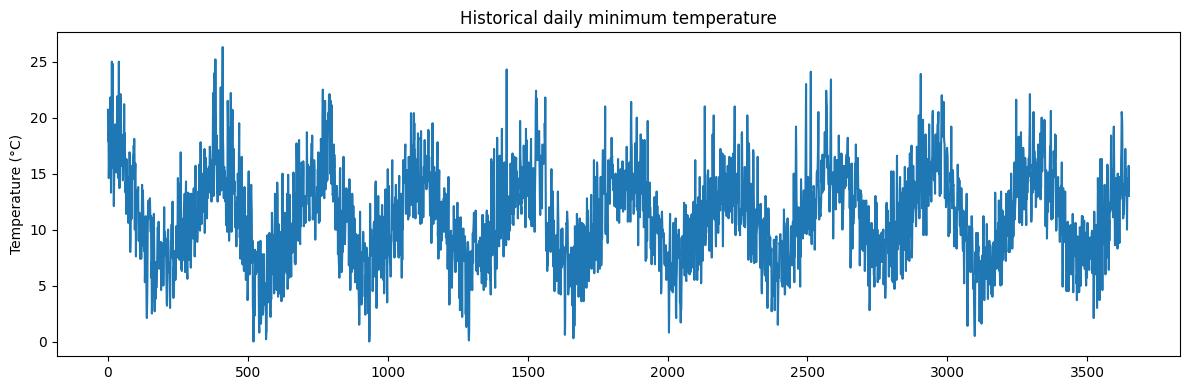

In [6]:
df['Temp'].plot(figsize=(12, 4), title='Historical daily minimum temperature')
plt.ylabel('Temperature (°C)'); plt.tight_layout(); plt.show()


In [8]:
data = df.copy()
data.set_index('Date', inplace=True)
for lag in [1, 2, 3, 7]:
    data[f'lag_{lag}'] = data['Temp'].shift(lag)
past = data['Temp'].shift(1)
data['mean_7'] = past.rolling(7).mean()
data['std_7'] = past.rolling(7).std()
data['month_sin'] = np.sin(2*np.pi*data.index.month/12)
data['month_cos'] = np.cos(2*np.pi*data.index.month/12)
data['day_sin'] = np.sin(2*np.pi*data.index.dayofyear/365.25)
data['day_cos'] = np.cos(2*np.pi*data.index.dayofyear/365.25)
data = data.dropna()
FEATURES = ['lag_1','lag_2','lag_3','lag_7','mean_7','std_7',
            'month_sin','month_cos','day_sin','day_cos']
X = data[FEATURES]

In [9]:
y = pd.Series(np.where(data['Temp'] < 10, 'Cold', 'Normal'), index=data.index, name='Tomorrow_Class')
print(y.value_counts())


Tomorrow_Class
Normal    2201
Cold      1442
Name: count, dtype: int64


In [10]:
split = int(len(data)*0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]
print('Train:', X_train.index.min().date(), 'to', X_train.index.max().date(), len(X_train))
print('Test :', X_test.index.min().date(), 'to', X_test.index.max().date(), len(X_test))
assert X_train.index.max() < X_test.index.min()


Train: 1981-01-08 to 1989-01-01 2914
Test : 1989-01-02 to 1990-12-31 729


In [11]:
model = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5, class_weight='balanced', random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)


                     Accuracy  BalancedAccuracy  MacroF1
RandomForest           0.8422            0.8420   0.8364
PersistenceBaseline    0.8244            0.8152   0.8152
              precision    recall  f1-score   support

        Cold      0.773     0.841     0.805       283
      Normal      0.893     0.843     0.867       446

    accuracy                          0.842       729
   macro avg      0.833     0.842     0.836       729
weighted avg      0.846     0.842     0.843       729



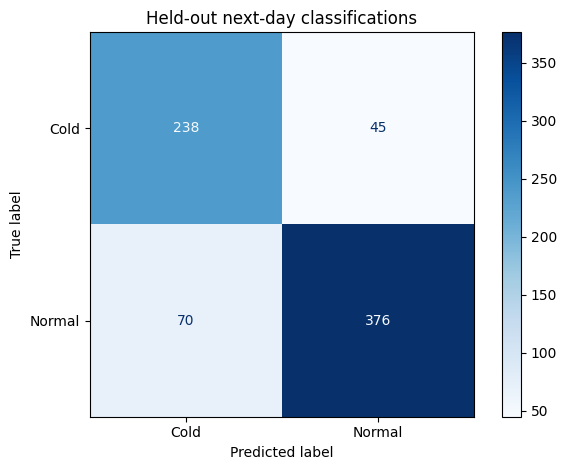

In [13]:
from sklearn.metrics import balanced_accuracy_score, classification_report, ConfusionMatrixDisplay

baseline = np.where(X_test['lag_1'] < 10, 'Cold', 'Normal')
def scores(actual, predicted):
    return {'Accuracy':float(accuracy_score(actual,predicted)),
            'BalancedAccuracy':float(balanced_accuracy_score(actual,predicted)),
            'MacroF1':float(f1_score(actual,predicted,average='macro'))}
metrics = {'RandomForest':scores(y_test,pred), 'PersistenceBaseline':scores(y_test,baseline)}
print(pd.DataFrame(metrics).T.round(4))
print(classification_report(y_test,pred,digits=3))
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=['Cold','Normal'],cmap='Blues')
plt.title('Held-out next-day classifications'); plt.tight_layout(); plt.show()

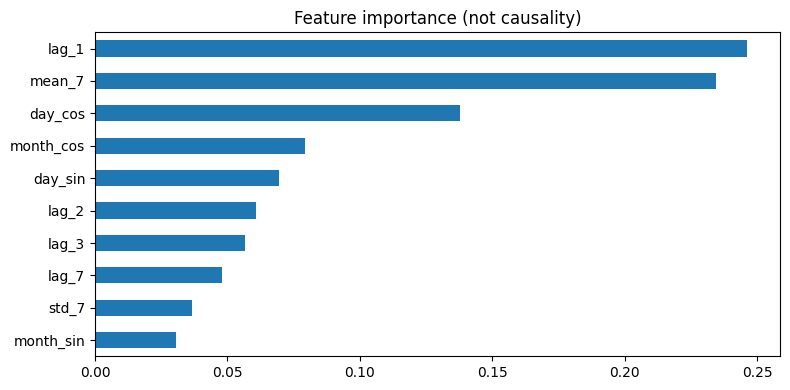

      date actual prediction baseline
1989-01-02 Normal     Normal   Normal
1989-01-03 Normal     Normal   Normal
1989-01-04 Normal     Normal   Normal
1989-01-05 Normal     Normal   Normal
1989-01-06   Cold     Normal   Normal
1989-01-07 Normal     Normal     Cold
1989-01-08 Normal     Normal   Normal
1989-01-09 Normal     Normal   Normal
1989-01-10 Normal     Normal   Normal
1989-01-11 Normal     Normal   Normal


In [16]:
from pathlib import Path
import json

importance = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(8,4),title='Feature importance (not causality)')
plt.tight_layout(); plt.show()
results = pd.DataFrame({'date':y_test.index, 'actual':y_test.to_numpy(), 'prediction':pred, 'baseline':baseline})
results.to_csv('test_predictions.csv',index=False)
Path('metrics.json').write_text(json.dumps(metrics,indent=2))
print(results.head(10).to_string(index=False))

In [18]:
# Example: Making a new prediction on the last available test sample
user_data = X_test.iloc[[0]]
prediction = model.predict(user_data)[0]
probabilities = dict(zip(model.classes_, model.predict_proba(user_data)[0].round(3)))

print('Predicted class for first test day:', prediction)
print('Class probabilities:', probabilities)

Predicted class for first test day: Normal
Class probabilities: {'Cold': np.float64(0.003), 'Normal': np.float64(0.997)}
